# Exocentric sync, step 08b

Refines the time offset between the phone video and the body camera session clock using signals at 30 Hz.

## Setup

Loads the config and the earlier reports and prints what was found.

In [1]:
import json, time, zipfile, warnings
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml, av, cv2
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
T_START = time.time()

# paths
ROOT = Path.cwd().resolve().parent
if not (ROOT / "configs" / "config.yaml").exists():
    raise RuntimeError(f"configs/config.yaml not found in {ROOT}. run this notebook from <PROJECT_ROOT>/notebooks.")
RAW, REP, INT = ROOT / "raw", ROOT / "reports", ROOT / "interim"
REP.mkdir(exist_ok=True)
INT.mkdir(exist_ok=True)
ROOT_VIDEO = RAW / "video_20261011_200844.mp4"

# settings
FPS = 30
STEP = 1 / FPS
LAG_RANGE = (90.0, 120.0)
NULL_RANGES = [(10.0, 80.0), (130.0, 250.0)]
EVENTS = [1030.0, 1348.0, 2512.0]
MIN_MARGIN = 0.03


def read_json(p):
    with open(p, "r", encoding="utf-8") as f:
        return json.load(f)


def load(fn, p):
    try:
        return fn(p)
    except Exception as e:
        print("could not read", p.name, "-", e)
        return None


def need(**kw):
    miss = [k for k, v in kw.items() if v is None or (hasattr(v, "__len__") and len(v) == 0)]
    if miss:
        raise ValueError("needs " + ", ".join(miss) + " from an earlier step")


def fl(x):
    x = float(x)
    return x if np.isfinite(x) else None


with open(ROOT / "configs" / "config.yaml", "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

anchor = load(read_json, REP / "04_time_anchor.json")
est0 = load(read_json, REP / "06_anchor_estimate.json")
summ5 = load(read_json, REP / "05_summary.json")
episodes = load(pd.read_csv, REP / "05_episodes.csv")
fit = load(pd.read_csv, REP / "04_chunk_clock_fit.csv")
manifest = load(pd.read_csv, REP / "raw_manifest.csv")

lag0, unc0, session_zero_us, episode_list = None, 1.5, None, []
try:
    lag0 = float(est0["lag_s"])
    unc0 = float(est0.get("uncertainty_s", 1.5))
    session_zero_us = int(summ5["session_zero_us"])
    episode_list = [(float(a), float(b)) for a, b in zip(episodes["start_s"], episodes["stop_s"])]
except Exception as e:
    print("setup problem:", repr(e))

# state used by the later cells
root_pts = root_motion = root_act = None
sigs, res = {}, {}
head_tl = None
n_dev = None
est_global, est_event = [], []
global_best, peak_corr, null_max, peak_all, null_all = {}, {}, {}, {}, {}
main_lags, null_lags = None, None
lag_final = None

try:
    print("episodes:", len(episode_list), "| chunk rows:", len(fit), "| manifest rows:", len(manifest))
    print("rows per device:", {d: int((fit["device"] == d).sum()) for d in sorted(fit["device"].unique())})
    print("root start utc:", anchor["root_start_utc"], "| root duration:", round(anchor["duration_stream_s"], 1), "s")
    print("first manual lag:", lag0, "s, uncertainty", unc0, "s")
    for i, (a, b) in enumerate(episode_list[:50], 1):
        print(f"episode {i}: {a:.1f} to {b:.1f} s")
except Exception as e:
    print("step failed:", e)

c:\workstation\3RD YEAR\ego_pipeline\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


episodes: 4 | chunk rows: 45 | manifest rows: 94
rows per device: {'head': 15, 'left': 15, 'right': 15}
root start utc: 2026-10-11T14:38:44.654044+00:00 | root duration: 2621.3 s
first manual lag: 104.0 s, uncertainty 1.5 s
episode 1: 272.0 to 980.0 s
episode 2: 1032.0 to 1345.0 s
episode 3: 1405.0 to 1752.0 s
episode 4: 1905.0 to 2505.0 s


## Root signal

Decodes the phone video, measures how much each frame changes and puts it on a regular 30 Hz grid. The per frame result is cached.

In [2]:
ROOT_CACHE = INT / "root_motion_30hz.npz"
USE_AREA = [True]


def to_grid(t, v, n=None):
    t = np.asarray(t, float)
    v = np.asarray(v, float)
    idx = np.rint(t / STEP).astype(np.int64)
    ok = (idx >= 0) & np.isfinite(v)
    idx, v = idx[ok], v[ok]
    if n is None:
        n = int(idx.max()) + 1
    keep = idx < n
    idx, v = idx[keep], v[keep]
    tot = np.bincount(idx, weights=v, minlength=n)
    cnt = np.bincount(idx, minlength=n)
    has = cnt > 0
    out = np.zeros(n)
    out[has] = tot[has] / cnt[has]
    pos = np.arange(n)
    out[~has] = np.interp(pos[~has], pos[has], out[has])
    return out


def prep(x, pct=98, smooth_s=0.3):
    x = np.minimum(np.asarray(x, float), np.percentile(x, pct))
    w = max(1, int(round(smooth_s * FPS)))
    x = np.convolve(x, np.ones(w) / w, mode="same")
    return (x - x.mean()) / x.std()


def small(frame):
    # 64 x 36 grey version of the frame
    if USE_AREA[0]:
        try:
            return frame.to_ndarray(width=64, height=36, format="gray", interpolation="AREA")
        except Exception:
            USE_AREA[0] = False
    return frame.to_ndarray(width=64, height=36, format="gray")


def decode_root(path):
    pts, mot = [], []
    t0 = time.time()
    with av.open(str(path)) as con:
        vs = con.streams.video[0]
        vs.thread_type = "AUTO"
        tb = float(vs.time_base)
        start = float(vs.start_time) * tb if vs.start_time is not None else 0.0
        total = vs.frames or int((anchor["duration_stream_s"] if anchor else 2600) * FPS)
        prev, last_t = None, 0.0
        bar = tqdm(total=total, unit="fr", desc="root video")
        for packet in con.demux(vs):
            for frame in packet.decode():
                g = small(frame).astype(np.int16)
                t = frame.pts * tb - start if frame.pts is not None else last_t + STEP
                last_t = t
                if prev is not None:
                    pts.append(t)
                    mot.append(float(np.abs(g - prev).mean()))
                prev = g
                bar.update(1)
        bar.close()
    pts, mot = np.array(pts), np.array(mot)
    o = np.argsort(pts, kind="stable")
    print(f"decoded {len(pts)} frames in {time.time() - t0:.0f} s ({len(pts) / (time.time() - t0):.0f} frames/s)")
    return pts[o], mot[o]


try:
    cached = None
    if ROOT_CACHE.exists():
        try:
            d = np.load(ROOT_CACHE)
            cached = (d["pts_s"], d["motion"])
            print("using cache:", len(cached[0]), "frames")
        except Exception as e:
            print("cache not readable, decoding again:", e)
    if cached is None:
        cached = decode_root(ROOT_VIDEO)
        tmp = INT / "root_motion_30hz_tmp.npz"
        np.savez(tmp, pts_s=cached[0], motion=cached[1])
        tmp.replace(ROOT_CACHE)
    root_pts, root_motion = cached
    root_act = prep(to_grid(root_pts, root_motion))
    print("root last frame time:", round(float(root_pts[-1]), 1), "s | root grid length:", len(root_act))
except Exception as e:
    print("step failed:", e)

root video: 100%|██████████| 79402/79402 [04:15<00:00, 310.60fr/s]


decoded 79401 frames in 256 s (310 frames/s)
root last frame time: 2621.3 s | root grid length: 78640


## Device signals

Builds the gyro activity and the head video activity on a 30 Hz grid of the session clock, then clips, smooths and z-scores them.

In [3]:
IMU = INT / "imu"


def pick(keys, exact=(), sub=()):
    keys = list(keys)
    low = {k.lower(): k for k in keys}
    for e in exact:
        if e in low:
            return low[e]
    for s_ in sub:
        for k in keys:
            if s_ in k.lower():
                return k
    return None


sigs.clear()

# (a) gyro activity
try:
    need(fit=fit, session_zero_us=session_zero_us)
    series = {}
    for dev, g in fit.groupby("device"):
        bases = list(g.sort_values("rank")["base"])
        files = [IMU / f"{b}.npz" for b in bases if (IMU / f"{b}.npz").exists()]
        if not files:
            files = [p for p in sorted(IMU.glob("*.npz")) if str(dev).lower() in p.name.lower()]
        ts, vs_ = [], []
        for p in files:
            d = np.load(p)
            if len(d["t_us"]) < 2:
                continue
            ts.append((d["t_us"].astype(np.int64) - session_zero_us) / 1e6)
            gy = np.asarray(d["gyro"], float)
            vs_.append(np.linalg.norm(gy.reshape(len(gy), -1), axis=1))
        print(f"{dev}: {len(vs_)} imu files of {len(bases)} chunks")
        if ts:
            series[dev] = (np.concatenate(ts), np.concatenate(vs_))
    need(series=series)
    n_dev = int(np.ceil(max(t.max() for t, _ in series.values()) * FPS)) + 1
    per_dev = []
    for dev, (t, v) in series.items():
        gr = to_grid(t, v, n_dev)
        per_dev.append((gr - gr.mean()) / gr.std())
    sigs["gyro"] = prep(np.mean(per_dev, axis=0))
except Exception as e:
    print("gyro signal failed:", e)

# (b) head video activity: timeline first
head_tl = None
try:
    need(fit=fit)
    heads = [d for d in fit["device"].unique() if "head" in str(d).lower()]
    if not heads:
        raise ValueError("no head device in the chunk fit table")
    hd = heads[0]
    tl_files = sorted(INT.glob(f"timeline_{hd}.npz")) or sorted(INT.glob("timeline_*head*.npz"))
    if not tl_files:
        raise ValueError("no timeline file for the head device")
    tl = np.load(tl_files[0], allow_pickle=True)
    print("timeline keys:", list(tl.keys()))
    k_sess = pick(tl.keys(), ["session_s", "session", "t_s"], ["session"])
    k_rank = pick(tl.keys(), ["rank"], ["rank"])
    k_loc = pick(tl.keys(), ["i", "local_i", "local", "frame_i", "local_frame", "i_local"], ["local"])
    print("using:", k_sess, k_rank, k_loc)
    if None in (k_sess, k_rank, k_loc):
        raise ValueError("session, rank and local frame arrays not found in the timeline")
    hrows = fit[fit["device"] == hd]
    head_tl = dict(dev=hd, sess=np.asarray(tl[k_sess], float), rank=np.asarray(tl[k_rank]).astype(int),
                   loc=np.asarray(tl[k_loc]).astype(int),
                   rank_base={int(r): b for r, b in zip(hrows["rank"], hrows["base"])})
    s_ = head_tl["sess"]
    print("head timeline frames:", len(s_), "| session range:", round(float(np.nanmin(s_)), 1), "to", round(float(np.nanmax(s_)), 1), "s")
except Exception as e:
    print("head timeline not available:", e)

# (b) head video activity: motion per frame
try:
    need(head_tl=head_tl, n_dev=n_dev)
    fr_files = sorted((INT / "frames").glob("*.npz"))
    if not fr_files:
        raise ValueError("no files in interim/frames")
    first = np.load(fr_files[0], allow_pickle=True)
    print("frame file keys:", list(first.keys()))
    k_mot = pick(first.keys(), ["motion", "mad", "motion_mad", "mean_abs_diff"], ["motion", "mad", "absdiff", "diff"])
    if k_mot is None:
        raise ValueError("no per frame motion array found")
    print("motion key:", k_mot)
    tt, vv = [], []
    for rk, base in head_tl["rank_base"].items():
        fp = INT / "frames" / f"{base}.npz"
        if not fp.exists():
            continue
        m = np.asarray(np.load(fp, allow_pickle=True)[k_mot], float).ravel()
        sel = np.where(head_tl["rank"] == rk)[0]
        li = head_tl["loc"][sel]
        okk = (li >= 0) & (li < len(m))
        tt.append(head_tl["sess"][sel][okk])
        vv.append(m[li[okk]])
    if not tt:
        raise ValueError("no head frames matched the timeline")
    sigs["head_video"] = prep(to_grid(np.concatenate(tt), np.concatenate(vv), n_dev))
    print("head video signal built from", len(tt), "clips")
except Exception as e:
    print("head video signal skipped:", e)

print("session grid length:", n_dev, "| root grid length:", None if root_act is None else len(root_act))
print("signals:", list(sigs))

head: 15 imu files of 15 chunks
left: 15 imu files of 15 chunks
right: 15 imu files of 15 chunks
timeline keys: ['n', 'rank', 'i', 'session_s', 'luma']
using: session_s rank i
head timeline frames: 77371 | session range: 0.1 to 2579.1 s
frame file keys: ['pts_time', 'digest', 'luma_mean', 'luma_std', 'motion', 'n_errors']
motion key: motion
head video signal built from 15 clips
session grid length: 77374 | root grid length: 78640
signals: ['gyro', 'head_video']


## Global lag search

Correlates the root signal with each device signal for lags from 90 to 120 s and compares the peak with lags where no match is expected.

In [4]:
def grid_index(intervals, n):
    parts = []
    for a, b in intervals:
        lo, hi = max(0, int(np.ceil(a * FPS))), min(n - 1, int(np.floor(b * FPS)))
        if hi >= lo:
            parts.append(np.arange(lo, hi + 1))
    return np.unique(np.concatenate(parts)) if parts else np.array([], dtype=int)


def corr_curve(x, y, ks, lag_samples):
    # x: device signal at k, y: root signal at k + lag
    xs = x[ks]
    out = np.full(len(lag_samples), np.nan)
    for m, ls in enumerate(lag_samples):
        j = ks + int(ls)
        ok = (j >= 0) & (j < len(y))
        if ok.sum() < 300:
            continue
        a = xs[ok]
        b = y[j[ok]]
        a = a - a.mean()
        b = b - b.mean()
        den = np.sqrt((a * a).sum() * (b * b).sum())
        if den > 0:
            out[m] = (a * b).sum() / den
    return out


def fwhm(lags, c, k):
    half = c[k] / 2
    lo = k
    while lo > 0 and c[lo - 1] >= half:
        lo -= 1
    hi = k
    while hi < len(c) - 1 and c[hi + 1] >= half:
        hi += 1
    return lags[hi] - lags[lo] + STEP


try:
    need(root_act=root_act, sigs=sigs)
    n_dev = len(next(iter(sigs.values())))
    ks_ep = grid_index(episode_list, n_dev)
    ks_all = np.arange(n_dev)
    main_s = np.arange(int(round(LAG_RANGE[0] * FPS)), int(round(LAG_RANGE[1] * FPS)) + 1)
    null_s = [np.arange(int(a * FPS), int(b * FPS) + 1) for a, b in NULL_RANGES]
    main_lags = main_s / FPS
    null_lags = [s / FPS for s in null_s]
    print("grid points inside episodes:", len(ks_ep), "| all:", len(ks_all))

    res.clear()
    est_global.clear()
    t_a = time.time()
    for mode, ks in (("episodes", ks_ep), ("all", ks_all)):
        for name, x in sigs.items():
            res[(mode, name)] = dict(main=corr_curve(x, root_act, ks, main_s),
                                     n1=corr_curve(x, root_act, ks, null_s[0]),
                                     n2=corr_curve(x, root_act, ks, null_s[1]))
    print(f"search took {time.time() - t_a:.0f} s")

    rows = []
    for (mode, name), r in res.items():
        c = r["main"]
        k = int(np.nanargmax(c))
        nm = float(np.nanmax(np.concatenate([r["n1"], r["n2"]])))
        w = fwhm(main_lags, c, k)
        margin = float(c[k]) - nm
        rows.append(dict(mode=mode, signal=name, best_lag_s=main_lags[k], peak_corr=c[k], fwhm_s=w,
                         null_max=nm, margin=margin, above=bool(margin >= MIN_MARGIN)))
        if mode == "episodes":
            global_best[name], peak_corr[name], null_max[name] = float(main_lags[k]), float(c[k]), nm
            est_global.append(dict(scope="global", signal=name, lag_s=float(main_lags[k]), correlation=float(c[k])))
        else:
            peak_all[name], null_all[name] = float(c[k]), nm
    print(pd.DataFrame(rows).round(3).to_string(index=False))
    for r_ in rows:
        verdict = "above" if r_["above"] else "NOT above"
        print(f"{r_['mode']} / {r_['signal']}: peak {r_['peak_corr']:.3f} at {r_['best_lag_s']:.2f} s, "
              f"null max {r_['null_max']:.3f} -> {verdict} the null by {MIN_MARGIN} (margin {r_['margin']:+.3f})")

    # one estimate per episode
    ep_rows = []
    for e, (a, b) in enumerate(episode_list, 1):
        ks = grid_index([(a, b)], n_dev)
        for name, x in sigs.items():
            c = corr_curve(x, root_act, ks, main_s)
            if np.isfinite(c).any():
                k = int(np.nanargmax(c))
                ep_rows.append(dict(episode=e, signal=name, lag_s=main_lags[k], corr=c[k]))
                est_global.append(dict(scope=f"episode_{e}", signal=name, lag_s=float(main_lags[k]), correlation=float(c[k])))
    if ep_rows:
        print(pd.DataFrame(ep_rows).head(50).round(3).to_string(index=False))
except Exception as e:
    print("step failed:", e)

grid points inside episodes: 59044 | all: 77374
search took 30 s
    mode     signal  best_lag_s  peak_corr  fwhm_s  null_max  margin  above
episodes       gyro     105.833      0.554   5.500     0.114   0.440   True
episodes head_video     105.800      0.645   4.600     0.050   0.594   True
     all       gyro     105.800      0.532   9.467     0.134   0.398   True
     all head_video     105.767      0.588   8.200     0.090   0.498   True
episodes / gyro: peak 0.554 at 105.83 s, null max 0.114 -> above the null by 0.03 (margin +0.440)
episodes / head_video: peak 0.645 at 105.80 s, null max 0.050 -> above the null by 0.03 (margin +0.594)
all / gyro: peak 0.532 at 105.80 s, null max 0.134 -> above the null by 0.03 (margin +0.398)
all / head_video: peak 0.588 at 105.77 s, null max 0.090 -> above the null by 0.03 (margin +0.498)
 episode     signal   lag_s  corr
       1       gyro 105.833 0.641
       1 head_video 105.767 0.760
       2       gyro 105.833 0.659
       2 head_video 105.8

## Event windows

Repeats the search in short windows of plus and minus 12 s around the three hands-up gestures.

In [5]:
try:
    need(root_act=root_act, sigs=sigs, main_lags=main_lags)
    est_event.clear()
    n_dev = len(next(iter(sigs.values())))
    ev_rows = []
    for ev in EVENTS:
        ks = np.arange(int(round((ev - 12) * FPS)), int(round((ev + 12) * FPS)) + 1)
        ks = ks[(ks >= 0) & (ks < n_dev)]
        for name, x in sigs.items():
            center = int(round(global_best.get(name, lag0) * FPS))
            samp = np.arange(center - 3 * FPS, center + 3 * FPS + 1)
            c = corr_curve(x, root_act, ks, samp)
            if not np.isfinite(c).any():
                print(f"event {ev:.0f} s / {name}: no valid window")
                continue
            k = int(np.nanargmax(c))
            ev_rows.append(dict(event_s=ev, signal=name, lag_s=samp[k] / FPS, corr=c[k]))
            est_event.append(dict(scope=f"event_{int(ev)}", signal=name, lag_s=float(samp[k] / FPS), correlation=float(c[k])))
    if ev_rows:
        print(pd.DataFrame(ev_rows).round(3).to_string(index=False))
except Exception as e:
    print("step failed:", e)

 event_s     signal   lag_s  corr
  1030.0       gyro 105.767 0.600
  1030.0 head_video 105.667 0.616
  1348.0       gyro 108.667 0.201
  1348.0 head_video 102.800 0.337
  2512.0       gyro 107.100 0.574
  2512.0 head_video 106.967 0.706


## Decision

Collects all estimates, picks the lag and saves the json and csv.

In [6]:
try:
    need(est_global=est_global, lag0=lag0)
    est = pd.DataFrame(est_global + est_event, columns=["scope", "signal", "lag_s", "correlation"])
    use = est[(est["correlation"] >= 0.15) & ((est["lag_s"] - lag0).abs() <= 2.0)]
    sd = float(use["lag_s"].std(ddof=1)) if len(use) > 1 else 0.0

    above = [n for n in sigs if n in null_max and (peak_corr[n] - null_max[n]) >= MIN_MARGIN]
    reasons = []
    if len(use) == 0:
        reasons.append("no estimate has correlation of at least 0.15 within 2 s of the manual lag")
    if not above:
        reasons.append(f"no global peak is above the null maximum by {MIN_MARGIN}")
    if len(use) > 0 and sd > 0.5:
        reasons.append(f"the standard deviation of the estimates is {sd:.2f} s (more than 0.5 s)")

    if reasons:
        status, reason = "fallback", "; ".join(reasons)
        lag_final, unc = lag0, unc0
    else:
        status = "ok"
        reason = f"global peak above the null for {', '.join(above)}; {len(use)} estimates agree within {sd:.2f} s"
        lag_final, unc = float(use["lag_s"].median()), max(0.1, sd)
    delta = lag_final - lag0

    method = ("Motion of the phone video and gyro activity of the body cameras (and head video motion when available) were put on a "
              "30 Hz grid, clipped, smoothed and z-scored, then correlated over lags from 90 to 120 s. "
              "The lag is the median of the best lags from the global search, the episodes and the gesture windows that passed the filters.")
    out = dict(lag_s=fl(lag_final), delta_s=fl(delta), uncertainty_s=fl(unc), status=status, reason=reason, method=method,
               signals_used=list(sigs), n_estimates_total=int(len(est)), n_estimates_used=int(len(use)),
               null_max={n: {"episodes": fl(null_max[n]), "all_times": fl(null_all.get(n, np.nan))} for n in null_max},
               peak_correlations={n: {"episodes": fl(peak_corr[n]), "all_times": fl(peak_all.get(n, np.nan))} for n in peak_corr},
               first_manual_lag_s=fl(lag0))
    with open(REP / "08b_exo_sync.json", "w", encoding="utf-8") as f:
        json.dump(out, f, indent=2)
    est.round(4).to_csv(REP / "08b_exo_sync_estimates.csv", index=False)

    print("status:", status)
    print("reason:", reason)
    print(f"lag = {lag_final:.3f} s, uncertainty = {unc:.3f} s, delta to manual = {delta:+.3f} s")
    print("estimates used:", len(use), "of", len(est))
except Exception as e:
    print("step failed:", e)

status: fallback
reason: the standard deviation of the estimates is 0.84 s (more than 0.5 s)
lag = 104.000 s, uncertainty = 1.500 s, delta to manual = +0.000 s
estimates used: 13 of 16


## Figures

Plots the correlation curves, the null ranges and the gesture windows.

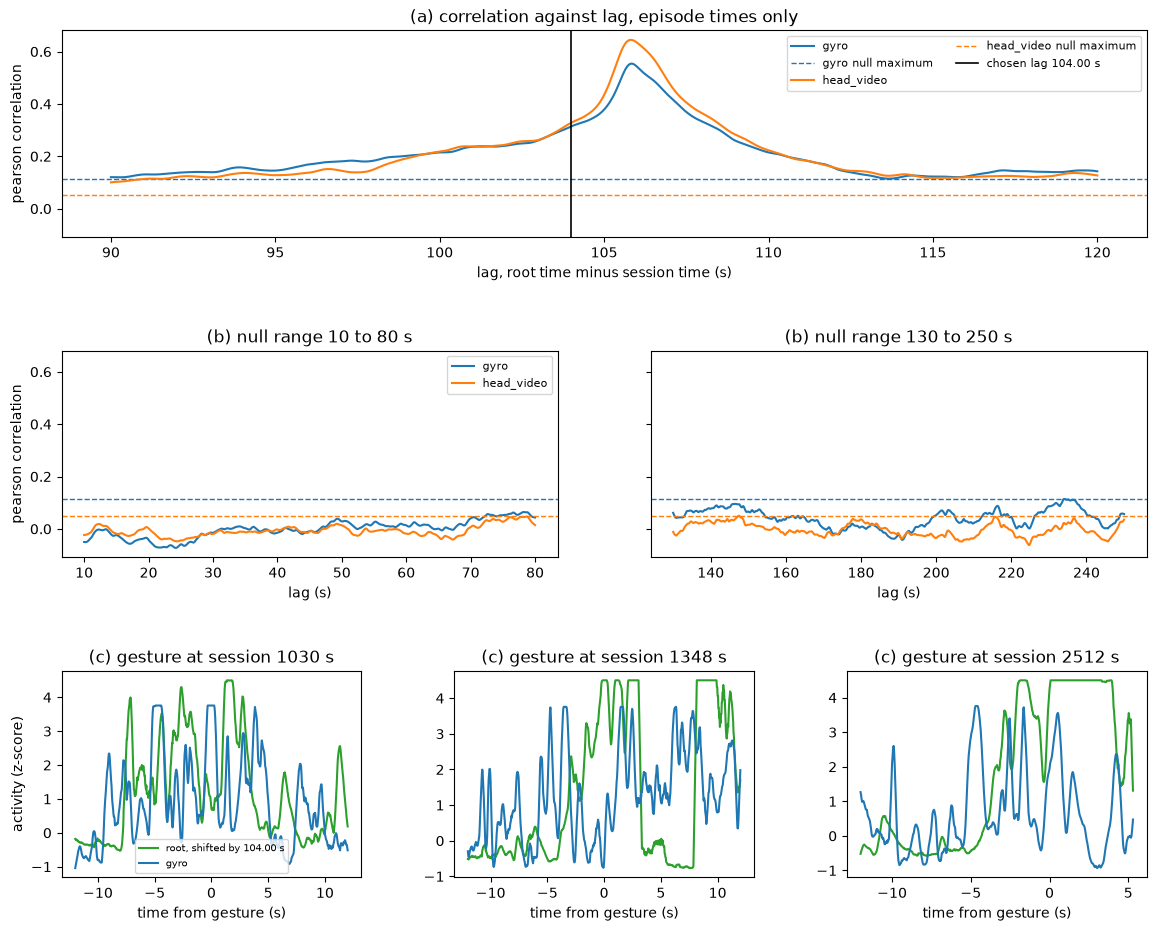

saved 08b_exo_sync.png


In [7]:
try:
    need(lag_final=lag_final, res=res, sigs=sigs)
    n = len(next(iter(sigs.values())))
    cols = {"gyro": "C0", "head_video": "C1"}
    fig = plt.figure(figsize=(14, 11))
    gs = fig.add_gridspec(3, 6, hspace=0.55, wspace=0.9)
    ax_a = fig.add_subplot(gs[0, :])
    ax_b1 = fig.add_subplot(gs[1, 0:3])
    ax_b2 = fig.add_subplot(gs[1, 3:6], sharey=ax_b1)

    lo, hi = np.inf, -np.inf
    for name in sigs:
        r = res[("episodes", name)]
        c = cols.get(name)
        ax_a.plot(main_lags, r["main"], color=c, label=name)
        ax_a.axhline(null_max[name], color=c, ls="--", lw=1, label=f"{name} null maximum")
        ax_b1.plot(null_lags[0], r["n1"], color=c, label=name)
        ax_b2.plot(null_lags[1], r["n2"], color=c, label=name)
        for ax in (ax_b1, ax_b2):
            ax.axhline(null_max[name], color=c, ls="--", lw=1)
        for arr in (r["main"], r["n1"], r["n2"]):
            lo, hi = min(lo, np.nanmin(arr)), max(hi, np.nanmax(arr))
    pad = 0.05 * (hi - lo)
    ax_a.set_ylim(lo - pad, hi + pad)
    ax_b1.set_ylim(lo - pad, hi + pad)
    ax_a.axvline(lag_final, color="k", lw=1.2, label=f"chosen lag {lag_final:.2f} s")
    ax_a.set_title("(a) correlation against lag, episode times only")
    ax_a.set_xlabel("lag, root time minus session time (s)")
    ax_a.set_ylabel("pearson correlation")
    ax_a.legend(fontsize=8, ncol=2)
    ax_b1.set_title("(b) null range 10 to 80 s")
    ax_b2.set_title("(b) null range 130 to 250 s")
    for ax in (ax_b1, ax_b2):
        ax.set_xlabel("lag (s)")
    ax_b1.set_ylabel("pearson correlation")
    ax_b1.legend(fontsize=8)
    plt.setp(ax_b2.get_yticklabels(), visible=False)

    off = np.arange(-12 * FPS, 12 * FPS + 1)
    for i, ev in enumerate(EVENTS):
        ax = fig.add_subplot(gs[2, 2 * i:2 * i + 2])
        si = int(round(ev * FPS)) + off
        ri = si + int(round(lag_final * FPS))
        ok = (si >= 0) & (si < n) & (ri >= 0) & (ri < len(root_act))
        ax.plot(off[ok] / FPS, root_act[ri[ok]], color="C2", label=f"root, shifted by {lag_final:.2f} s")
        if "gyro" in sigs:
            ax.plot(off[ok] / FPS, sigs["gyro"][si[ok]], color="C0", label="gyro")
        ax.set_title(f"(c) gesture at session {ev:.0f} s")
        ax.set_xlabel("time from gesture (s)")
        if i == 0:
            ax.set_ylabel("activity (z-score)")
            ax.legend(fontsize=7)
    fig.savefig(REP / "08b_exo_sync.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("saved", (REP / "08b_exo_sync.png").name)
except Exception as e:
    print("step failed:", e)

## Gesture sheet

Shows root and head frames around each gesture so the lag can be checked by eye.

In [8]:
FONT = cv2.FONT_HERSHEY_SIMPLEX
TW = 150
OFFS = np.arange(-4, 5) * 0.25


def put(tile, text, y, x=2):
    cv2.putText(tile, text, (x, y), FONT, 0.33, (255, 255, 255), 1, cv2.LINE_AA)


def frame_at(con, vs, t_rel, start):
    tb = float(vs.time_base)
    target = t_rel + start
    con.seek(int(max(target, 0) / tb), stream=vs, backward=True, any_frame=False)
    for k, fr in enumerate(con.decode(vs)):
        if fr.pts is None:
            continue
        if fr.pts * tb >= target - 1e-3:
            return fr.to_ndarray(format="bgr24")
        if k > 900:
            break
    return None


def clip_path(base):
    stem = manifest["rel_path"].map(lambda s: Path(str(s).replace("\\", "/")).stem)
    sel = manifest[stem == str(base)]
    conv = sel[sel["rel_path"].str.contains("VIDEO_CONVERTED", case=False)]
    for rel in list(conv["rel_path"]) + list(sel["rel_path"]):
        rel = Path(str(rel).replace("\\", "/"))
        for r_ in (RAW, ROOT):
            if (r_ / rel).exists():
                return r_ / rel
    hits = list(RAW.rglob(f"{base}.mp4"))
    return hits[0] if hits else None


def make_row(imgs, labels, default_h):
    hs = [round(im.shape[0] * TW / im.shape[1]) for im in imgs if im is not None]
    h = max(hs) if hs else default_h
    tiles = []
    for im, lb in zip(imgs, labels):
        tile = np.full((h + 14, TW, 3), 40, np.uint8)
        if im is not None:
            rs = cv2.resize(im, (TW, round(im.shape[0] * TW / im.shape[1])), interpolation=cv2.INTER_AREA)
            tile[:min(h, rs.shape[0])] = rs[:h]
        else:
            put(tile, "no frame", h // 2)
        put(tile, lb, h + 10)
        tiles.append(tile)
    return np.hstack(tiles)


def add_side(row, lines):
    side = np.full((row.shape[0], 80, 3), 20, np.uint8)
    for i, ln in enumerate(lines):
        put(side, ln, 14 + 12 * i)
    return np.hstack([side, row])


clips = {}
rcon = None
try:
    need(lag_final=lag_final)
    # root video
    rcon = av.open(str(ROOT_VIDEO))
    rvs = rcon.streams.video[0]
    rvs.thread_type = "AUTO"
    r_start = float(rvs.start_time) * float(rvs.time_base) if rvs.start_time is not None else 0.0
    rot = -90.0
    try:
        tag = rvs.metadata.get("rotate")
        if tag is not None:
            rot = -float(tag)
    except Exception:
        pass
    print("root rotation used:", rot, "degrees")

    def upright(img):
        if img is None:
            return None
        h, w = img.shape[:2]
        if abs(rot) == 180:
            return cv2.rotate(img, cv2.ROTATE_180)
        if w > h and rot == -90:
            return cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)
        if w > h and rot == 90:
            return cv2.rotate(img, cv2.ROTATE_90_COUNTERCLOCKWISE)
        return img

    # head clips through the timeline
    have_head = head_tl is not None and manifest is not None
    if have_head:
        order = np.argsort(head_tl["sess"])
        ss = head_tl["sess"][order]

    def head_frame(t):
        k = int(np.searchsorted(ss, t))
        cand = [c for c in (k - 1, k) if 0 <= c < len(ss)]
        k = min(cand, key=lambda c: abs(ss[c] - t))
        if abs(ss[k] - t) > 0.5:
            return None
        idx = order[k]
        base = head_tl["rank_base"].get(int(head_tl["rank"][idx]))
        if base is None:
            return None
        if base not in clips:
            p = clip_path(base)
            if p is None:
                clips[base] = None
            else:
                con = av.open(str(p))
                vs = con.streams.video[0]
                vs.thread_type = "AUTO"
                st = float(vs.start_time) * float(vs.time_base) if vs.start_time is not None else 0.0
                fps = float(vs.average_rate or vs.guessed_rate or FPS)
                clips[base] = (con, vs, st, fps)
        if clips[base] is None:
            return None
        con, vs, st, fps = clips[base]
        img = frame_at(con, vs, head_tl["loc"][idx] / fps, st)
        return None if img is None else cv2.rotate(img, cv2.ROTATE_180)

    if not have_head:
        print("head frames not available, the head rows will be empty")

    rows = []
    for ev in EVENTS:
        r_imgs, r_lab, h_imgs, h_lab = [], [], [], []
        for k in OFFS:
            rt = ev + lag_final + k
            r_imgs.append(upright(frame_at(rcon, rvs, rt, r_start)))
            r_lab.append(f"root {rt:.2f}s")
            st_ = ev + k
            h_imgs.append(head_frame(st_) if have_head else None)
            h_lab.append(f"sess {st_:.2f}s")
        rows.append(add_side(make_row(r_imgs, r_lab, 267), [f"event", f"{ev:.0f} s", "root"]))
        rows.append(add_side(make_row(h_imgs, h_lab, 84), ["event", f"{ev:.0f} s", "head"]))
        print("done event", ev)
    sheet = np.vstack(rows)
    ok, buf = cv2.imencode(".png", sheet)
    buf.tofile(str(REP / "08b_gesture_sheet.png"))
    print("saved", "08b_gesture_sheet.png", sheet.shape[1], "x", sheet.shape[0])
except Exception as e:
    print("step failed:", e)
finally:
    for v in clips.values():
        if v is not None:
            v[0].close()
    if rcon is not None:
        rcon.close()

root rotation used: -90.0 degrees
done event 1030.0
done event 1348.0
done event 2512.0
saved 08b_gesture_sheet.png 1430 x 1137


## Summary

Saves the summary, zips the 08b files and prints the result.

In [9]:
try:
    need(lag_final=lag_final)
    out = read_json(REP / "08b_exo_sync.json")
    summary = dict(run_time_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"),
                   notebook_seconds=round(time.time() - T_START, 1),
                   root_video=ROOT_VIDEO.name,
                   root_frames=None if root_pts is None else int(len(root_pts)),
                   signals_used=out["signals_used"], status=out["status"], reason=out["reason"],
                   lag_s=out["lag_s"], delta_s=out["delta_s"], uncertainty_s=out["uncertainty_s"],
                   first_manual_lag_s=out["first_manual_lag_s"],
                   peak_correlations=out["peak_correlations"], null_max=out["null_max"])
    with open(REP / "08b_summary.json", "w", encoding="utf-8") as f:
        json.dump(summary, f, indent=2)

    zpath = REP / "share_08b.zip"
    files = sorted(REP.glob("08b_*"))
    with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
        for p in files:
            z.write(p, arcname=p.name)

    print("status:", summary["status"])
    print(f"lag {summary['lag_s']:.3f} s, uncertainty {summary['uncertainty_s']:.3f} s, delta {summary['delta_s']:+.3f} s")
    print("reason:", summary["reason"])
    print("files in zip:", [p.name for p in files])
    print("zip:", zpath)
except Exception as e:
    print("step failed:", e)

status: fallback
lag 104.000 s, uncertainty 1.500 s, delta +0.000 s
reason: the standard deviation of the estimates is 0.84 s (more than 0.5 s)
files in zip: ['08b_exo_sync.json', '08b_exo_sync.png', '08b_exo_sync_estimates.csv', '08b_gesture_sheet.png', '08b_summary.json']
zip: C:\workstation\3RD YEAR\ego_pipeline\reports\share_08b.zip
